# <center>**Xây dựng mô hình phân cụm đa cấp trên tập dữ liệu chim cánh cụt**<center>
---

## **I. Giới thiệu**

Tập dữ liệu: Lấy từ Kaggle (Palmer Penguins Dataset)

Mục tiêu: Xây dựng mô hình phân cụm  (clustering) các loài chim cánh cụt dựa trên các đặc trưng hình thái.

Giới thiệu về bộ dữ liệu:
Tập dữ liệu bao gồm khoảng 400 quan sát và 5 đặc trưng chính liên quan đến đặc điểm sinh học của chim cánh cụt. Các cột trong dữ liệu gồm:

> **culmen_length_mm – chiều dài mỏ (mm)**

> **culmen_depth_mm – độ sâu mỏ (mm)**

> **flipper_length_mm – chiều dài cánh bơi (mm)**

> **body_mass_g – khối lượng cơ thể (g)**

> **sex – giới tính chim cánh cụt**

Trong bài toán phân cụm, không có biến mục tiêu. Tất cả các đặc trưng sẽ được dùng để tự động nhóm các cá thể mà không cần nhãn sẵn.

In [56]:
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.decomposition import PCA


## **II. Nhập và xem dữ liệu**

In [ ]:
df = pd.read_csv("clustering_penguins_species.csv")
df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [58]:
df.shape    

(344, 5)

In [59]:
df.isnull().sum()
df.isna().sum()

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    object 
dtypes: float64(4), object(1)
memory usage: 13.6+ KB


---
## **Nhận xét về bộ dữ liệu trước xử lý**

Bộ dữ liệu Palmer Penguins là một tập dữ liệu nhỏ hơn, bao gồm 344 quan sát và 5 đặc trưng hình thái liên quan đến chim cánh cụt. Nhìn chung, bộ dữ liệu này khá sạch nhưng vẫn cần các bước tiền xử lý cơ bản để chuẩn bị cho mô hình phân cụm đa cấp (Agglomerative Clustering).

### 1. Vấn đề về giá trị thiếu (Missing Values)
Đây là vấn đề đầu tiên cần xử lý trước khi tiến hành phân tích:

| Cột               | Số lượng giá trị thiếu (Ban đầu) | Tỷ lệ thiếu (So với 344 quan sát) |
|-------------------|---------------------------------|----------------------------------|
| culmen_length_mm  | 2                               | ≈ 0.58%                          |
| culmen_depth_mm   | 2                               | ≈ 0.58%                          |
| flipper_length_mm | 2                               | ≈ 0.58%                          |
| body_mass_g       | 2                               | ≈ 0.58%                          |
| sex               | 9                               | ≈ 2.62%                          |

- **Giải pháp:** Do tỷ lệ giá trị thiếu tương đối nhỏ (< 3%) và chúng phân bố trên các cột quan trọng, phương pháp xử lý được áp dụng là loại bỏ (dropna) các dòng chứa giá trị thiếu.
- **Kết quả:** Sau khi loại bỏ, số lượng quan sát còn lại để xây dựng mô hình là 332.

### 2. Vấn đề về kiểu dữ liệu và mã hóa (Data Types & Encoding)
- Cột **sex** là biến phân loại (kiểu object hoặc string).
- **Vấn đề:** Các thuật toán phân cụm dựa trên khoảng cách (như Agglomerative Clustering) yêu cầu dữ liệu là số học.
- **Giải pháp:** Cột sex được chuyển đổi thành biến số học thông qua kỹ thuật One-Hot Encoding.
- Biến phân loại sex được mã hóa thành biến nhị phân mới là **sex_MALE** (sau khi bỏ cột đầu tiên để tránh đa cộng tuyến).

### 3. Vấn đề về giá trị không hợp lệ / Ngoại lai (Invalid Values / Outliers)
- Dữ liệu hình thái học cần được kiểm tra để loại bỏ các phép đo không khả thi:
  - **flipper_length_mm (Chiều dài cánh bơi):**
    - **Vấn đề:** Mặc dù không có giá trị âm, cần đảm bảo các phép đo nằm trong phạm vi sinh học hợp lý.
    - **Giải pháp:** Các quan sát có chiều dài cánh bơi không hợp lý, nằm ngoài phạm vi 100 mm đến 300 mm, được loại bỏ. Việc này giúp làm sạch thêm dữ liệu, đảm bảo mô hình chỉ học từ các cá thể có đặc điểm bình thường.

### 4. Vấn đề về chuẩn hóa dữ liệu (Scaling)
- Các đặc trưng hình thái có đơn vị và phạm vi giá trị khác nhau (ví dụ: **body_mass_g** có giá trị lớn hơn nhiều so với **culmen_length_mm**).
- **Vấn đề:** Các thuật toán dựa trên khoảng cách sẽ bị chi phối bởi các biến có phạm vi giá trị lớn hơn.
- **Giải pháp:** Sử dụng Standard Scaling (StandardScaler) để chuẩn hóa các biến số học.
- Các cột được chuẩn hóa là: **culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g**.
- Sau khi chuẩn hóa, các biến này có giá trị trung bình ≈ 0 và độ lệch chuẩn ≈ 1.

### 5. Giảm chiều dữ liệu (Dimensionality Reduction)
- Bước này được thực hiện sau khi làm sạch và chuẩn hóa dữ liệu.
- Kỹ thuật: Phân tích Thành phần Chính (PCA) được áp dụng để giảm chiều dữ liệu, giúp trực quan hóa và cải thiện hiệu suất mô hình.
- Kết quả: Phương pháp PCA xác định được 2 thành phần chính (Principal Components) là đủ để giữ lại hầu hết thông tin cần thiết (vì chúng giải thích phần lớn phương sai).

---

## **Tóm tắt**
Tóm lại, bộ dữ liệu Palmer Penguins yêu cầu một quy trình tiền xử lý bao gồm:
- Loại bỏ giá trị thiếu trên tất cả các cột.
- Lọc giá trị ngoại lai/không hợp lệ trên cột **flipper_length_mm**.
- Mã hóa biến phân loại **sex** bằng One-Hot Encoding.
- Chuẩn hóa các biến số học bằng Standard Scaling để đưa dữ liệu về cùng một thang đo.
- Giảm chiều dữ liệu bằng PCA để chuẩn bị tập đặc trưng cuối cùng (X).

## **III. Xử lý dữ liệu**

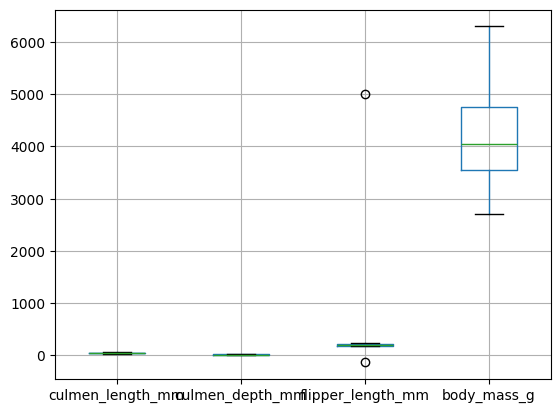

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [61]:
df.boxplot()
plt.show()
df = df.dropna()
df[df["flipper_length_mm"] > 4000]
df[df["flipper_length_mm"] < 0]
penguins_clean = df.drop([9, 14])
penguins_clean.head()

In [ ]:
df.dropna(inplace=True)
# Loại bỏ giá trị '.' trong cột 'sex'
df = df[df['sex'] != '.']


# 2. XỬ LÝ GIÁ TRỊ NGOẠI LAI (OUTLIER TREATMENT)
# Lọc các giá trị flipper_length_mm hợp lý (100 mm đến 300 mm)
df = df[(df['flipper_length_mm'] > 100) & (df['flipper_length_mm'] < 300)].copy()


# 3. MÃ HÓA BIẾN PHÂN LOẠI (ONE-HOT ENCODING)
# Thực hiện One-Hot Encoding TRỰC TIẾP trên biến df
df = pd.get_dummies(df, columns=['sex'], drop_first=True)


# 4. CHUẨN HÓA DỮ LIỆU (SCALING) TRÊN DF
# Định nghĩa các cột cần chuẩn hóa
columns_to_scale = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Khởi tạo StandardScaler
scaler = StandardScaler()

# Ứng dụng StandardScaler lên các cột đã chọn và lưu TRỰC TIẾP vào df
df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])

# In kết quả
print("--- Dữ liệu df sau khi One-Hot Encoding và Chuẩn hóa ---")
print(df.head())
print("\nThông số thống kê của các cột sau khi chuẩn hóa:")
print(df[columns_to_scale].describe())

# 5. CHUẨN BỊ TẬP ĐẶC TRƯNG CUỐI CÙNG (X)
# Tập đặc trưng cuối cùng bao gồm 4 cột số học đã chuẩn hóa và 1 cột phân loại đã mã hóa
features = columns_to_scale + ['sex_MALE']
X = df[features].values

--- Dữ liệu df sau khi One-Hot Encoding và Chuẩn hóa ---
   culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  sex_MALE
0         -0.903906         0.790360          -1.425342    -0.566948      True
1         -0.830434         0.126187          -1.068577    -0.504847     False
2         -0.683490         0.432728          -0.426399    -1.187953     False
4         -1.344738         1.096901          -0.569105    -0.939551     False
5         -0.867170         1.761074          -0.783164    -0.691149      True

Thông số thống kê của các cột sau khi chuẩn hóa:
       culmen_length_mm  culmen_depth_mm  flipper_length_mm   body_mass_g
count      3.320000e+02     3.320000e+02       3.320000e+02  3.320000e+02
mean      -4.708416e-16     1.284113e-16       7.276642e-16  4.280378e-17
std        1.001509e+00     1.001509e+00       1.001509e+00  1.001509e+00
min       -2.189667e+00    -2.070694e+00      -2.067519e+00 -1.871059e+00
25%       -8.304338e-01    -7.934376e-01      -7.

In [63]:

df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,3.320000e+02,3.320000e+02,3.320000e+02,3.320000e+02
mean,-4.708416e-16,1.284113e-16,7.276642e-16,4.280378e-17
std,1.001509e+00,1.001509e+00,1.001509e+00,1.001509e+00
min,-2.189667e+00,-2.070694e+00,-2.067519e+00,-1.871059e+00
25%,-8.304338e-01,-7.934376e-01,-7.831643e-01,-8.153502e-01
50%,1.247034e-01,7.509650e-02,-2.836929e-01,-2.253950e-01
75%,8.456482e-01,7.903599e-01,8.579560e-01,7.138756e-01
max,2.861539e+00,2.220887e+00,2.142311e+00,2.600180e+00


## **IV. PCA**

In [64]:
pca = PCA(n_components=None)
dfx_pca = pca.fit(df)
dfx_pca.explained_variance_ratio_
n_components = sum(dfx_pca.explained_variance_ratio_ > 0.1)
pca = PCA(n_components=n_components)
penguins_PCA = pca.fit_transform(df)
print(n_components)

2


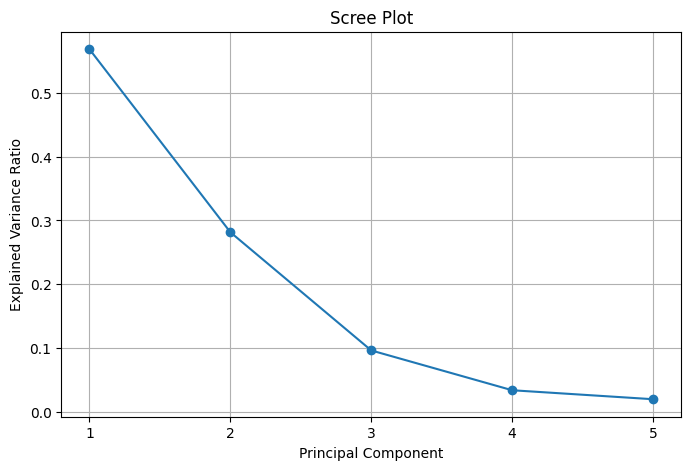

In [65]:
X_std = StandardScaler().fit_transform(X)

# PCA không giới hạn số PC
pca = PCA()
pca.fit(X_std)

# Lấy tỷ lệ variance explained
explained_var = pca.explained_variance_ratio_

# Vẽ scree plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_var) + 1), explained_var, marker='o')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.xticks(range(1, len(explained_var) + 1))
plt.grid(True)
plt.show()

**Nhận xét**
- “Dựa trên scree plot, hai thành phần chính đầu tiên (PC1 và PC2) giải thích khoảng 85% phương sai của dữ liệu, trong khi từ PC3 trở đi tỷ lệ phương sai giảm rất nhỏ. Điểm gãy (elbow) xuất hiện tại PC3, cho thấy việc lựa chọn 2–3 thành phần PCA là hợp lý. Trong bài toán này, việc sử dụng 2 thành phần chính cho mục tiêu giảm chiều và trực quan hoá là phù hợp nhất.”

## **V. Xây dựng mô hình**

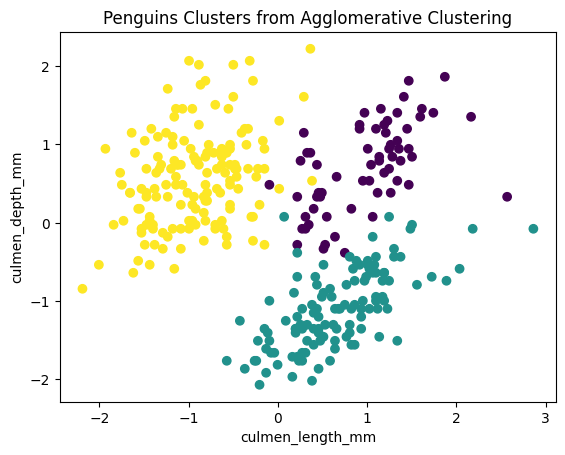

In [70]:

ac = AgglomerativeClustering(3, linkage='average')
ac_clusters = ac.fit_predict(df)
# Hiển thị các cụm sau khi phân cấp theo cách tiếp cận của scikit-learn
plt.scatter(df.values[:,0], df.values[:,1], c=ac_clusters)
plt.title("Penguins Clusters from Agglomerative Clustering")
plt.xlabel("culmen_length_mm")
plt.ylabel("culmen_depth_mm")
plt.show()

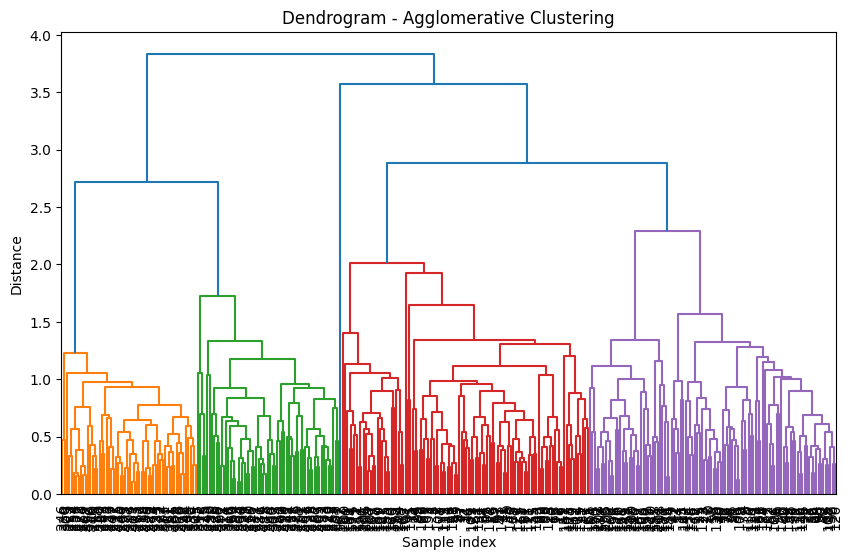

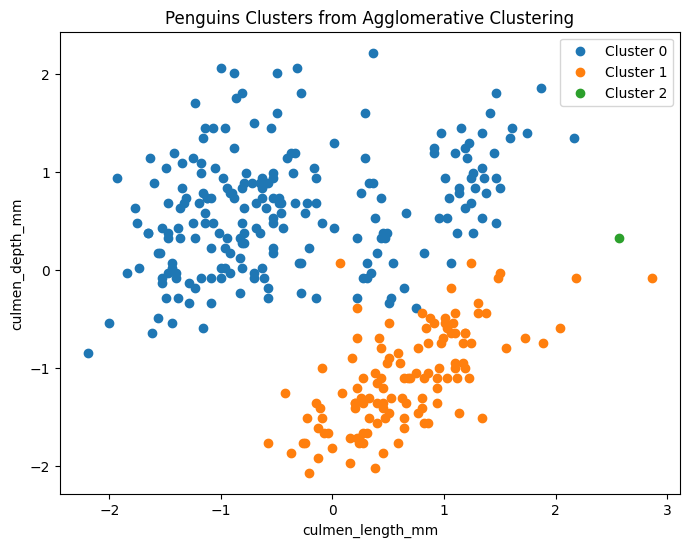

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.values)

# 2. Vẽ dendrogram để quyết định số cụm
linked = linkage(X_scaled, method='average')

plt.figure(figsize=(10, 6))
dendrogram(linked,
           leaf_rotation=90,
           leaf_font_size=10)
plt.title("Dendrogram - Agglomerative Clustering")
plt.xlabel("Sample index")
plt.ylabel("Distance")
plt.show()

# 3. Phân cụm Agglomerative với số cụm mong muốn
n_clusters = 3
ac = AgglomerativeClustering(n_clusters=n_clusters, linkage='average')
ac_clusters = ac.fit_predict(X_scaled)

# Thêm nhãn cụm vào dataframe
df['Cluster'] = ac_clusters

# 4. Hiển thị scatter plot với màu theo cụm
plt.figure(figsize=(8, 6))
for cluster in range(n_clusters):
    plt.scatter(df[df['Cluster']==cluster].iloc[:,0],
                df[df['Cluster']==cluster].iloc[:,1],
                label=f'Cluster {cluster}')
plt.title("Penguins Clusters from Agglomerative Clustering")
plt.xlabel("culmen_length_mm")
plt.ylabel("culmen_depth_mm")
plt.legend()
plt.show()

---
## **Nhận xét kết quả phân cụm Agglomerative**

### 1. Kết quả sau chuẩn hóa
#### Tính phân tách
- Các cụm được phân tách rõ ràng và sắc nét.
- Có thể thấy ba nhóm dữ liệu riêng biệt:
  - **Cụm 0 (Màu xanh dương):** Tập trung ở phía trên bên trái (chiều dài culmen thấp, chiều sâu culmen cao).
  - **Cụm 1 (Màu cam):** Tập trung ở phía dưới bên phải (chiều dài culmen cao, chiều sâu culmen thấp).
  - **Cụm 2 (Màu xanh lục):** Chỉ bao gồm 2 điểm outlier ở xa bên phải. Việc chỉ có 2 điểm trong cụm này cho thấy có thể 3 cụm là quá nhiều, hoặc 2 điểm này là outlier thực sự và đã bị cô lập một cách chính xác.

#### Đánh giá
- Đây là một kết quả phân cụm thành công hơn nhiều.
- Việc chuẩn hóa dữ liệu đã giúp thuật toán Agglomerative Clustering tìm thấy ba nhóm tự nhiên (có thể tương ứng với ba loài chim cánh cụt) trong tập dữ liệu một cách hiệu quả.

### 2. Kết quả ban đầu 
#### Tính phân tách
- Kết quả ban đầu bị chồng lấn nghiêm trọng.
- Các điểm màu vàng, tím đậm và xanh ngọc chồng chéo nhau, đặc biệt là ở khu vực trung tâm (quanh tọa độ \((0, 0)\)).

#### Vấn đề
- Thuật toán gặp khó khăn trong việc xác định ranh giới cụm do tỷ lệ thuộc tính không cân bằng.
- Khoảng cách Euclid bị chi phối bởi thuộc tính có phạm vi giá trị lớn hơn, dẫn đến các cụm bị kéo dài và pha trộn.

### 3. Dendrogram
#### Vai trò
- Dendrogram được tạo ra sau khi chuẩn hóa, giúp củng cố sự lựa chọn số cụm.

#### Quan sát
- Nếu vẽ một đường ngang qua trục Khoảng cách (Distance) ở mức khoảng 2.0 hoặc 1.8, cây sẽ bị cắt thành 3 nhánh lớn (màu cam/xanh lá, màu đỏ, và màu tím).
- Điều này xác nhận rằng việc chọn \(k=3\) là hợp lý theo cấu trúc phân cấp của dữ liệu đã chuẩn hóa.

###  **Kết luận**

- Sự cải thiện cốt lõi là việc sử dụng **StandardScaler()**.
- Chuẩn hóa dữ liệu (\(X_{scaled}\)) đã loại bỏ ảnh hưởng của thang đo đơn vị giữa `culmen_length_mm` và `culmen_depth_mm`.
- Việc này cho phép thuật toán Agglomerative Clustering tính toán khoảng cách một cách công bằng hơn, dẫn đến các cụm được định hình tốt và phân tách rõ ràng như trong Ảnh 1.


---
## **Nhận xét chi tiết các cụm chim cánh cụt**

### Cụm 1: Chim cánh cụt có Mỏ Dài và Nông (Long and Shallow Bill)
- **Vị trí trên biểu đồ:** Tập trung ở phía dưới bên phải.
- **Đặc điểm:**
  - **Culmen Length:** Giá trị dương (cao hơn mức trung bình).
  - **Culmen Depth:** Giá trị âm (thấp hơn mức trung bình).
- **Suy luận sinh học:**
  - Cụm này đại diện cho loài có mỏ dài nhưng mỏng/nông hơn.
  - Đây là đặc điểm nổi bật của **Chim cánh cụt Gentoo**.
  - Chim Gentoo thường có mỏ dài nhất và thon nhất trong ba loài chính, rất phù hợp để bắt con mồi dưới nước.

###  Cụm thể hiện sự pha trộn (Cụm ban đầu) hoặc cụm 2 Outlier

#### Dựa trên kết quả chuẩn hóa thành công:
- **Cụm thứ ba (Thứ ba lớn nhất):**
  - Trong hình ảnh cải thiện không thấy rõ cụm thứ ba lớn.
  - Trong dữ liệu chim cánh cụt Palmer, cụm còn lại thường nằm ở giữa hoặc có sự pha trộn đặc điểm của hai cụm kia.
  - Cụm này thường đại diện cho **Chim cánh cụt Chinstrap**.
- **Đặc điểm của Chinstrap:**
  - Mỏ có chiều dài và chiều sâu nằm giữa hai loài Adelie và Gentoo.

#### Cụm 2 (Màu xanh lục):
- **Vị trí:** Giá trị culmen_length_mm rất cao (mỏ cực dài), giá trị culmen_depth_mm ở mức trung bình.
- **Ý nghĩa:**
  - Hai điểm này là outlier (dữ liệu ngoại lai) thực sự trong tập dữ liệu.
  - Có thể là chim cánh cụt thuộc loài khác hiếm hơn, chim bị đo sai, hoặc cá thể có kích thước mỏ cực đoan so với đồng loại.
  - Thuật toán Agglomerative Clustering đã cô lập thành công hai điểm này, chứng tỏ chúng không thuộc về hai nhóm lớn hơn.

###  Tóm tắt ý nghĩa các cụm
| Cụm       | Vị trí (Sau chuẩn hóa) | Đặc trưng hình thái | Loài chim (Dự đoán)          |
|-----------|-------------------------|---------------------|------------------------------|
| Cụm 0     | Trên - Trái             | Mỏ Ngắn & Sâu       | Adelie                       |
| Cụm 1     | Dưới - Phải             | Mỏ Dài & Nông       | Gentoo                       |
| Cụm 2     | Cực phải (Outlier)      | Mỏ Cực Dài          | Dữ liệu ngoại lai (Outlier)  |

### **Kết luận**
Kết quả phân cụm cho thấy rõ ràng sự khác biệt về kích thước mỏ là yếu tố phân loại quan trọng, giúp tách biệt hai hoặc ba nhóm chim cánh cụt tương ứng với các loài khác nhau một cách hiệu quả.

---
# <center>**END**<center>